# Cross-dataset transfer (NQ and SQuAD)
Run after `rl_ar_pipeline.ipynb` has defined its functions (any config; every stage is cached). Uses only the cached tables in `runs/`.
Block B produces the frozen-policy transfer results reported in the paper (`runs/*/*/results/xfer_from_*.pkl`, `transfer_both_directions.csv`).
Blocks A and C are supplementary analyses of RL-AR-Lite.

frontier:   0%|          | 0/10 [00:00<?, ?it/s]

A done in 69.3 min

=== Best F1 achievable within each static-k token budget (Lite = retrieval + query features; seed means) ===


,dataset,model,static_k,static_f1,static_tokens,lite_f1_within_budget,lite_lam,dF1_lite,sup_f1_within_budget,dF1_sup,lite_min_tokens_within_1pt,token_saving_pct_within_1pt
0,NQ,Llama-3.2-1B,1,0.472,236.608,0.472,0.50,-0.000,0.390,-0.082,235.628,0.414
1,NQ,Llama-3.2-1B,2,0.517,381.187,0.513,0.10,-0.004,0.390,-0.128,348.416,8.597
2,NQ,Llama-3.2-1B,3,0.514,526.055,0.513,0.10,-0.000,0.390,-0.124,348.416,33.768
3,NQ,Llama-3.2-3B,1,0.517,237.517,0.511,0.50,-0.006,0.446,-0.071,222.581,6.288
4,NQ,Llama-3.2-3B,2,0.588,381.972,0.584,0.15,-0.004,0.446,-0.142,363.991,4.707
5,NQ,Llama-3.2-3B,3,0.602,526.860,0.604,0.02,0.002,0.446,-0.156,417.452,20.766
6,NQ,Qwen2.5-3B,1,0.522,221.153,0.511,0.50,-0.011,0.461,-0.061,234.492,-6.032
7,NQ,Qwen2.5-3B,2,0.564,371.892,0.561,0.15,-0.002,0.461,-0.102,350.689,5.701
8,NQ,Qwen2.5-3B,3,0.579,522.212,0.575,0.00,-0.004,0.461,-0.118,445.113,14.764
9,NQ,Mistral-7B-v0.3,1,0.514,237.355,0.479,0.50,-0.035,0.436,-0.078,250.379,-5.487


Summary by static k: mean dF1 (Lite / Supervised-Lite), configs where Lite >= static, mean token saving at <=1 F1-point loss


,mean_dF1_lite,mean_dF1_sup,n_lite_geq_static,n,mean_saving_pct_1pt
static_k,,,,,
1,-0.014,-0.059,0,10,-3.905
2,-0.000,-0.108,3,10,7.292
3,-0.001,-0.130,3,10,19.536


transfer:   0%|          | 0/5 [00:00<?, ?it/s]

B done in 27.5 min

=== Frozen-policy transfer vs in-domain policy (same target test set; Holm over all rows) ===


,source,target,model,policy,f1_transfer,f1_in_domain,dF1,p_wilcoxon,tok_transfer,tok_in_domain,k_transfer,k_in_domain,p_holm,dTok_pct
0,NQ,SQuAD,Llama-3.2-1B,full,0.402,0.427,-0.025,0.000,361.877,400.113,1.784,2.159,0.007,-9.556
1,NQ,SQuAD,Llama-3.2-1B,lite,0.396,0.432,-0.035,0.002,274.620,330.037,1.740,2.304,0.041,-16.791
2,SQuAD,NQ,Llama-3.2-1B,full,0.519,0.506,0.014,0.073,484.311,436.969,2.143,1.832,0.954,10.834
3,SQuAD,NQ,Llama-3.2-1B,lite,0.512,0.506,0.006,0.233,391.968,339.652,2.068,1.713,1.000,15.403
4,NQ,SQuAD,Llama-3.2-3B,full,0.468,0.462,0.006,0.257,417.740,394.706,2.311,2.119,1.000,5.836
5,NQ,SQuAD,Llama-3.2-3B,lite,0.460,0.473,-0.012,0.004,326.421,343.836,2.254,2.426,0.058,-5.065
6,SQuAD,NQ,Llama-3.2-3B,full,0.584,0.587,-0.003,0.572,503.344,486.007,2.284,2.151,1.000,3.567
7,SQuAD,NQ,Llama-3.2-3B,lite,0.595,0.593,0.002,0.844,447.621,425.645,2.451,2.302,1.000,5.163
8,NQ,SQuAD,Llama-3.1-8B,full,0.443,0.484,-0.041,0.000,359.479,413.608,1.736,2.283,0.003,-13.087
9,NQ,SQuAD,Llama-3.1-8B,lite,0.436,0.475,-0.039,0.000,263.725,330.193,1.631,2.288,0.002,-20.130


mean_dF1  n_sig  mean_dTok_pct  mean_k_shift
source target policy                                              
NQ     SQuAD  full      -0.018      2         -4.528         1.976
              lite      -0.024      2        -10.636         1.978
SQuAD  NQ     full       0.004      0         11.775         2.233
              lite       0.007      0         18.790         2.411


=== RL-AR-Lite decision profile on test (pooled over seeds) ===


,dataset,model,mean_k,share_k0,share_k1,share_k2,share_k3,P_retrieve_if_helps,P_retrieve_if_not,mean_k_if_deeper_helps,mean_k_if_not
0,NQ,Llama-3.2-1B,1.713,0.000,0.508,0.271,0.221,1.000,1.000,1.761,1.702
1,NQ,Llama-3.2-3B,2.302,0.001,0.124,0.447,0.428,0.999,0.998,2.380,2.279
2,NQ,Qwen2.5-3B,2.168,0.008,0.206,0.395,0.391,0.993,0.990,2.223,2.155
3,NQ,Mistral-7B-v0.3,1.845,0.012,0.233,0.654,0.101,0.990,0.986,1.930,1.820
4,NQ,Llama-3.1-8B,1.789,0.005,0.390,0.415,0.190,0.998,0.990,1.903,1.767
5,SQuAD,Llama-3.2-1B,2.304,0.000,0.250,0.196,0.554,1.000,1.000,2.428,2.277
6,SQuAD,Llama-3.2-3B,2.426,0.002,0.141,0.286,0.571,0.998,0.998,2.436,2.423
7,SQuAD,Qwen2.5-3B,2.297,0.003,0.157,0.380,0.460,0.998,0.994,2.381,2.272
8,SQuAD,Mistral-7B-v0.3,2.300,0.006,0.225,0.232,0.537,0.994,0.993,2.410,2.268
9,SQuAD,Llama-3.1-8B,2.288,0.002,0.194,0.318,0.486,0.999,0.997,2.397,2.257


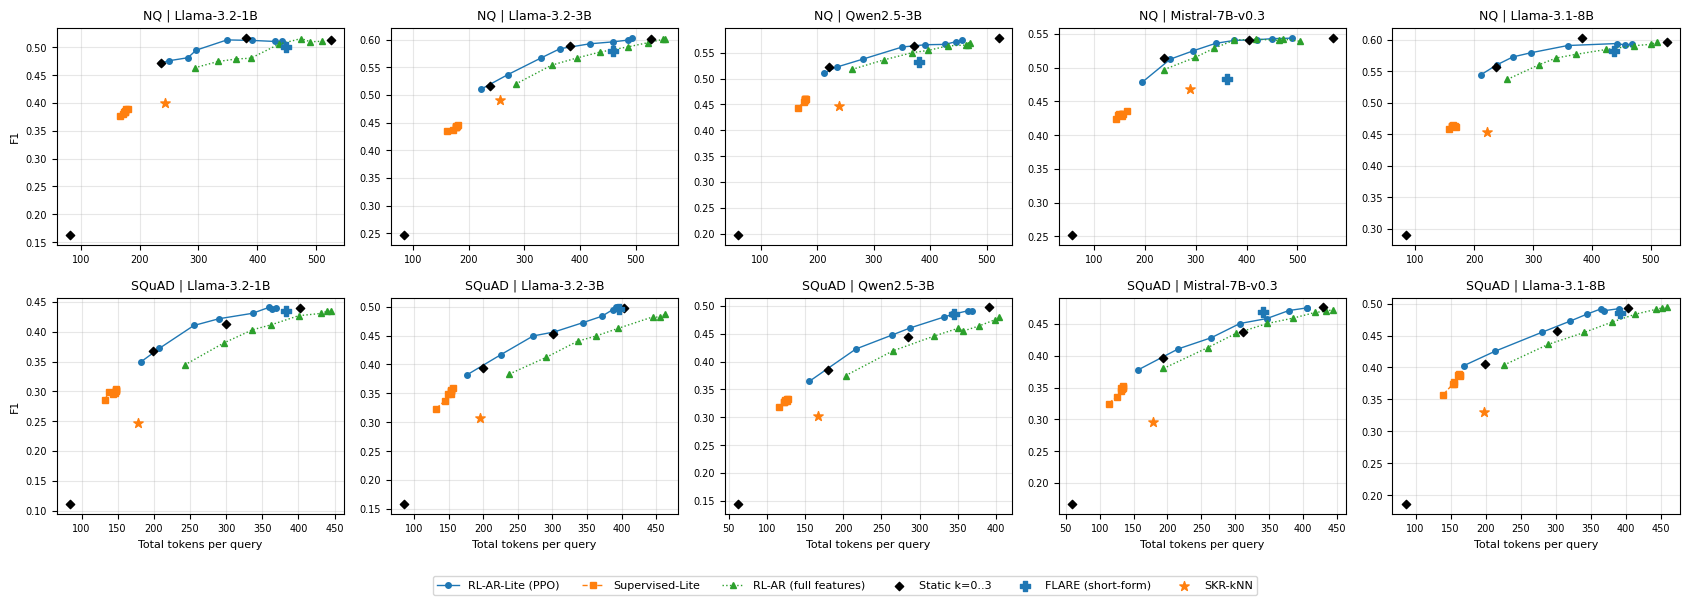

Saved: /kaggle/working/rlar/summary/matched_budget.csv, transfer_both_directions.csv, lite_decision_profile.csv, frontier_lite_grid.(png|pdf)


In [25]:
# ================= CROSS-DATASET TRANSFER AND RL-AR-LITE FRONTIER (NQ, SQuAD; cached tables only, no LLM / GPU) =================
# Run the notebook top to bottom with ANY config first (every stage is cached, so this is fast);
# that defines the functions used here. Then run this cell. It is resumable: every policy run is saved.
#   A. Lambda-sweep frontier for RL-AR-Lite (pre-generation features: retrieval scores + query) and
#      Supervised-Lite, plus "best F1 within each static-k token budget" (fair Pareto comparison).
#   B. Frozen-policy transfer in BOTH directions for every model, Full and Lite.
#   C. Depth-decision profile of RL-AR-Lite: k distribution and when it retrieves (mechanism).
CONFIGS     = [(d, m) for d in ["nq", "squad"] for m in ["llama1b", "llama3b", "qwen3b", "mistral7b", "llama8b"]]
LITE        = ("ret", "query")
FULL        = ("unc", "ret", "query")
FRONT_SEEDS = SEEDS[:3]
SUMDIR      = f"{OUT_ROOT}/summary"; os.makedirs(SUMDIR, exist_ok=True)
LAT_KEYS    = ["t_embed", "t_search", "t_flare_embed", "t_flare_search", "t_flare_gen"] + [f"t_gen_{k}" for k in K_OPTIONS]
MNAME = {"llama1b": "Llama-3.2-1B", "llama3b": "Llama-3.2-3B", "qwen3b": "Qwen2.5-3B", "mistral7b": "Mistral-7B-v0.3", "llama8b": "Llama-3.1-8B"}
DNAME = {"nq": "NQ", "squad": "SQuAD"}

def load_config(ds, mk):
    """Point every global the policy/evaluation code reads at (ds, mk)."""
    global DATASET_KEY, MODEL_KEY, DATA_DIR, RUN_DIR, TAB, MU, SD, T_REF, LAT
    DATASET_KEY, MODEL_KEY = ds, mk
    DATA_DIR, RUN_DIR = f"{OUT_ROOT}/data/{ds}", f"{OUT_ROOT}/runs/{ds}/{mk}"
    TAB = {s: load_pkl(f"{RUN_DIR}/tables_{s}.pkl") for s in ["train", "val", "test"]}
    MU, SD = TAB["train"]["X"].mean(0), TAB["train"]["X"].std(0) + 1e-6
    T_REF = float(np.mean(TAB["train"]["NIN"][:, -1] - TAB["train"]["NIN"][:, 0]))
    lat = {r["qid"]: r for r in read_jsonl(f"{RUN_DIR}/latency_test.jsonl")}
    LAT = {k: np.array([lat.get(q, {}).get(k, np.nan) for q in TAB["test"]["qids"]]) for k in LAT_KEYS}

def seed_mean(res, m): return float(np.mean([np.nanmean(ev[m]) for ev in res.values()]))
def pt(res): return dict(f1=seed_mean(res, "f1"), em=seed_mean(res, "em"), k=seed_mean(res, "k"),
                         total_tokens=seed_mean(res, "total_tokens"), latency_ms=seed_mean(res, "latency_ms"))

def best_within_budget(points, budget, key="total_tokens"):
    ok = [p for p in points if p[key] <= budget + 1e-9]
    return max(ok, key=lambda p: p["f1"]) if ok else None

# ---------------- A. Lite frontier + matched-budget comparison ----------------
FR_ROWS, BUDGET_ROWS = [], []
t0 = time.time()
for ds, mk in tqdm(CONFIGS, desc="frontier"):
    load_config(ds, mk)
    lite, sup = [], []
    for lam in LAMBDA_GRID:
        tag = str(lam).replace(".", "p")
        r1 = run_learned(f"lamlite_{tag}_ppo", "ppo", groups=LITE, lam=lam, seeds=FRONT_SEEDS)
        r2 = run_learned(f"lamlite_{tag}_sup", "supervised", groups=LITE, lam=lam, seeds=FRONT_SEEDS)
        lite.append(dict(lam=lam, **pt(r1))); sup.append(dict(lam=lam, **pt(r2)))
        FR_ROWS += [dict(dataset=ds, model=mk, method="RL-AR-Lite (PPO)", lam=lam, **pt(r1)),
                    dict(dataset=ds, model=mk, method="Supervised-Lite", lam=lam, **pt(r2))]
    for k in K_OPTIONS:
        st = pt(run_static(k)); FR_ROWS.append(dict(dataset=ds, model=mk, method=f"Static k={k}", lam=np.nan, **st))
        if k == 0: continue
        b_l, b_s = best_within_budget(lite, st["total_tokens"]), best_within_budget(sup, st["total_tokens"])
        reach = [p for p in lite if p["f1"] >= st["f1"] - 0.01]
        BUDGET_ROWS.append(dict(dataset=DNAME[ds], model=MNAME[mk], static_k=k, static_f1=st["f1"], static_tokens=st["total_tokens"],
                                lite_f1_within_budget=b_l["f1"] if b_l else np.nan, lite_lam=b_l["lam"] if b_l else np.nan,
                                dF1_lite=(b_l["f1"] - st["f1"]) if b_l else np.nan,
                                sup_f1_within_budget=b_s["f1"] if b_s else np.nan,
                                dF1_sup=(b_s["f1"] - st["f1"]) if b_s else np.nan,
                                lite_min_tokens_within_1pt=min(p["total_tokens"] for p in reach) if reach else np.nan,
                                token_saving_pct_within_1pt=(100 * (1 - min(p["total_tokens"] for p in reach) / st["total_tokens"])) if reach else np.nan))
FRONT_LITE = pd.DataFrame(FR_ROWS); FRONT_LITE.to_csv(f"{SUMDIR}/frontier_lite_all.csv", index=False)
BUDGET = pd.DataFrame(BUDGET_ROWS); BUDGET.to_csv(f"{SUMDIR}/matched_budget.csv", index=False)
print(f"A done in {(time.time()-t0)/60:.1f} min")
print("\n=== Best F1 achievable within each static-k token budget (Lite = retrieval + query features; seed means) ===")
display(BUDGET.round(3))
print("Summary by static k: mean dF1 (Lite / Supervised-Lite), configs where Lite >= static, mean token saving at <=1 F1-point loss")
display(BUDGET.groupby("static_k").agg(mean_dF1_lite=("dF1_lite", "mean"), mean_dF1_sup=("dF1_sup", "mean"),
        n_lite_geq_static=("dF1_lite", lambda s: int((s >= 0).sum())), n=("dF1_lite", "size"),
        mean_saving_pct_1pt=("token_saving_pct_within_1pt", "mean")).round(3))

# ---------------- B. Transfer, both directions, Full and Lite ----------------
def transfer(src, tgt, mk, groups, tag, seeds=SEEDS):
    path = f"{OUT_ROOT}/runs/{tgt}/{mk}/results/xfer_from_{src}_{tag}.pkl"
    load_config(tgt, mk)
    if os.path.exists(path) and not FORCE_REPOLICY: return load_pkl(path)
    S = {s: load_pkl(f"{OUT_ROOT}/runs/{src}/{mk}/tables_{s}.pkl") for s in ["train", "val"]}
    s_mu, s_sd = S["train"]["X"].mean(0), S["train"]["X"].std(0) + 1e-6
    s_tref = float(np.mean(S["train"]["NIN"][:, -1] - S["train"]["NIN"][:, 0]))
    Xtr, Xva = feats(S["train"], groups, s_mu, s_sd), feats(S["val"], groups, s_mu, s_sd)
    Rtr, Rva = reward_matrix(S["train"], tref=s_tref), reward_matrix(S["val"], tref=s_tref)
    out = {}
    for sd_ in seeds:
        actor, _ = train_ppo(Xtr, Rtr, Xva, Rva, sd_)
        ki = greedy(actor, feats(TAB["test"], groups, s_mu, s_sd))
        out[sd_] = evaluate(TAB["test"], ki, draft="unc" in groups, upfront="ret" in groups,
                            policy_ms=policy_latency_ms(actor, Xtr.shape[1]))
    save_pkl(out, path); return out

XR = []; t0 = time.time()
for mk in tqdm(sorted({m for _, m in CONFIGS}), desc="transfer"):
    for src, tgt in [("nq", "squad"), ("squad", "nq")]:
        for tag, groups, indom in [("full", FULL, "main_ppo"), ("lite", LITE, "main_ppo_nodraft")]:
            res = transfer(src, tgt, mk, groups, tag)
            ind = load_pkl(f"{OUT_ROOT}/runs/{tgt}/{mk}/results/{indom}.pkl")
            a, b = np.nanmean(np.stack([e["f1"] for e in res.values()]), 0), np.nanmean(np.stack([e["f1"] for e in ind.values()]), 0)
            d = a - b; p = sps.wilcoxon(d, zero_method="zsplit").pvalue if np.any(d != 0) else 1.0
            XR.append(dict(source=DNAME[src], target=DNAME[tgt], model=MNAME[mk], policy=tag,
                           f1_transfer=seed_mean(res, "f1"), f1_in_domain=seed_mean(ind, "f1"), dF1=d.mean(), p_wilcoxon=p,
                           tok_transfer=seed_mean(res, "total_tokens"), tok_in_domain=seed_mean(ind, "total_tokens"),
                           k_transfer=seed_mean(res, "k"), k_in_domain=seed_mean(ind, "k")))
XFER2 = pd.DataFrame(XR); XFER2["p_holm"] = holm(XFER2.p_wilcoxon.values)
XFER2["dTok_pct"] = 100 * (XFER2.tok_transfer / XFER2.tok_in_domain - 1)
XFER2.to_csv(f"{SUMDIR}/transfer_both_directions.csv", index=False)
print(f"B done in {(time.time()-t0)/60:.1f} min")
print("\n=== Frozen-policy transfer vs in-domain policy (same target test set; Holm over all rows) ===")
display(XFER2.round(3))
display(XFER2.groupby(["source", "target", "policy"]).agg(mean_dF1=("dF1", "mean"), n_sig=("p_holm", lambda s: int((s < 0.05).sum())),
        mean_dTok_pct=("dTok_pct", "mean"), mean_k_shift=("k_transfer", "mean")).round(3))

# ---------------- C. Decision profile of RL-AR-Lite (main lambda) ----------------
PR = []
for ds, mk in CONFIGS:
    load_config(ds, mk); te = TAB["test"]
    res = load_pkl(f"{RUN_DIR}/results/main_ppo_nodraft.pkl")
    ks = np.concatenate([e["k"] for e in res.values()]); n_s = len(res)
    helped = np.tile(te["F1"][:, 1:].max(1) > te["F1"][:, 0], n_s)
    deeper_helps = np.tile(te["F1"][:, 3] > te["F1"][:, 1], n_s)      # does k=3 beat k=1 for this query?
    row = dict(dataset=DNAME[ds], model=MNAME[mk], mean_k=ks.mean(),
               **{f"share_k{k}": float((ks == k).mean()) for k in K_OPTIONS},
               P_retrieve_if_helps=float((ks[helped] > 0).mean()), P_retrieve_if_not=float((ks[~helped] > 0).mean()),
               mean_k_if_deeper_helps=float(ks[deeper_helps].mean()) if deeper_helps.any() else np.nan,
               mean_k_if_not=float(ks[~deeper_helps].mean()) if (~deeper_helps).any() else np.nan)
    PR.append(row)
PROFILE = pd.DataFrame(PR); PROFILE.to_csv(f"{SUMDIR}/lite_decision_profile.csv", index=False)
print("\n=== RL-AR-Lite decision profile on test (pooled over seeds) ==="); display(PROFILE.round(3))

# ---------------- Figure: Lite frontier grid ----------------
DS_L, MD_L = ["nq", "squad"], ["llama1b", "llama3b", "qwen3b", "mistral7b", "llama8b"]
fig, axes = plt.subplots(2, 5, figsize=(17, 6), squeeze=False)
for i, ds in enumerate(DS_L):
    for j, mk in enumerate(MD_L):
        ax = axes[i, j]; F = FRONT_LITE[(FRONT_LITE.dataset == ds) & (FRONT_LITE.model == mk)]
        old = pd.read_csv(f"{OUT_ROOT}/runs/{ds}/{mk}/tables/frontier.csv")
        for meth, mk_, src in [("RL-AR-Lite (PPO)", "o-", F), ("Supervised-Lite", "s--", F), ("RL-AR (PPO)", "^:", old)]:
            d = src[src.method == meth].sort_values("total_tokens")
            ax.plot(d.total_tokens, d.f1, mk_, ms=4, lw=1, label="RL-AR (full features)" if meth == "RL-AR (PPO)" else meth)
        d = F[F.method.str.startswith("Static")]; ax.scatter(d.total_tokens, d.f1, marker="D", c="k", s=18, zorder=5, label="Static k=0..3")
        for nm, m_ in [("FLARE (short-form)", "P"), ("SKR-kNN", "*")]:
            d = old[old.method == nm]; ax.scatter(d.total_tokens, d.f1, marker=m_, s=50, zorder=5, label=nm)
        ax.set_title(f"{DNAME[ds]} | {MNAME[mk]}", fontsize=9); ax.grid(alpha=0.3); ax.tick_params(labelsize=7)
        if i == 1: ax.set_xlabel("Total tokens per query", fontsize=8)
        if j == 0: ax.set_ylabel("F1", fontsize=8)
h, l = [], []
for ax in axes.flat:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l: h.append(hh); l.append(ll)
fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(f"{SUMDIR}/frontier_lite_grid.png", dpi=250, bbox_inches="tight"); fig.savefig(f"{SUMDIR}/frontier_lite_grid.pdf", bbox_inches="tight")
plt.show()
print(f"Saved: {SUMDIR}/matched_budget.csv, transfer_both_directions.csv, lite_decision_profile.csv, frontier_lite_grid.(png|pdf)")